# I-94 Interstate Highway: Predicting Traffic

**Goal:** The aim of this project is to identify a few indicators of heavy traffic such as weather type, time of day, etc. 

Our analysis will explore:

1) Traffic volume
2) Traffic volume: Time indicators
3) Traffic volume: Weather indicators

The dataset we will be using for this project is from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume) donated by John Hogue. The dataset was collected between Minneapolis and Saint Paul for westbound traffic on I-94 from 2012-2018. 

**Analysis Findings:** 

Three time indicators of traffic volume:

* Warmer months (March-October) typically have more cars on the road than the colder month (November-February) per day at any given time
* Traffic is higher during the weekdays (Monday-Friday) and lesser on the weekends
* During the week, most cars are on the road from 7-8 a.m. and 4-5 p.m. while weekend traffic is more stagnant

Three weather condition indicators of traffic volume:

* Light rain and snow
* Proximity thunderstorm with drizzle
* Shower snow

For further details, see the full analysis below.

## Data Exploration

**Overview**

We will first start be exploring the data and gaining helpful information about the data types, columns, etc. for our analysis. This project will be graph heavy so we will begin by importing a few important modules for our analysis. 

In [1]:
#import necessary modules for project analysis
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
#read dataset into project file
metro = pd.read_csv('Metro_Interstate_Traffic_Volume.csv')

#print first 5 rows
metro.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
#print last 5 rows
metro.tail()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
48199,NaN,283.45,0.0,0.0,75,Clouds,broken clouds,2018-09-30 19:00:00,3543
48200,NaN,282.76,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 20:00:00,2781
48201,NaN,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,NaN,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450
48203,NaN,282.12,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 23:00:00,954


The `Series.head()` and `Series.tail()` attributes let us quickly scan all the columns with the first and last five rows in the dataset. The only things that jump out at me are the 'holiday' column is filled with NaN values (likely because most days are not holidays) and the temperature is not is Celsius (likely Kelvin).

In [14]:
#overview information of 'metro' dataset
metro.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


This dataset contains 9 columns and 48,204 rows of data. With only one row, 'holiday', containing null values. 

Below is an overview of each column:


|Column Title|Dtype|Desciption|
|:--|:--|--:|
|holiday     |           Categorical  |  US National holidays plus regional holiday, Minnesota State Fair|
|temp         |          Numeric     |   Average temp in kelvin|
|rain_1h       |         Numeric    |    Amount in mm of rain that occurred in the hour|
|snow_1h       |         Numeric   |     Amount in mm of snow that occurred in the hour|
|clouds_all     |        Numeric    |    Percentage of cloud cover|
|weather_main   |        Categorical |   Short textual description of the current weather|
|weather_description |   Categorical |   Longer textual description of the current weather|
|date_time         |     DateTime    |   Hour of the data collected in local CST time|
|traffic_volume    |     Numeric     |   Hourly I-94 ATR 301 reported westbound traffic volume|



Before we continue, let's take a look at the unique values in 'weather_main' and 'weather_description'.

**Targeted Exploration: Weather Categories**

In [5]:
#list of unique values in 'weather_main' column
metro['weather_main'].unique()

<StringArray>
[      'Clouds',        'Clear',         'Rain',      'Drizzle',
         'Mist',         'Haze',          'Fog', 'Thunderstorm',
         'Snow',       'Squall',        'Smoke']
Length: 11, dtype: str

There are eleven unique values in the 'weather_main' column.

In [6]:
#list of unique values in 'weather_description' column
wd_unique = metro['weather_description'].unique()
wd_unique

<StringArray>
[                   'scattered clouds',                       'broken clouds',
                     'overcast clouds',                        'sky is clear',
                          'few clouds',                          'light rain',
             'light intensity drizzle',                                'mist',
                                'haze',                                 'fog',
               'proximity shower rain',                             'drizzle',
                       'moderate rain',                'heavy intensity rain',
              'proximity thunderstorm',        'thunderstorm with light rain',
    'proximity thunderstorm with rain',                          'heavy snow',
             'heavy intensity drizzle',                                'snow',
        'thunderstorm with heavy rain',                       'freezing rain',
                         'shower snow',                 'light rain and snow',
         'light intensity shower rain'

There are thirty-eight unique values in the 'weather_description' column. 

Before we move on, let's classify the number of unique 'weather_description'(s) that there are per 'weather_main' categories.

In [7]:
#dictionary with key from 'wd_unique'
category_keywords = {
    'Clouds': ['clouds'],
    'Rain/Drizzle/Mist': ['rain', 'drizzle', 'mist'],
    'Thunderstorm': ['thunderstorm'],
    'Snow': ['snow'],
    'Haze/Fog': ['haze', 'fog'],
    'Smoke': ['smoke'],
    'Clear': ['clear'],
    'Squall': ['squall'],
}

#dictionary of unique 'weather_description'(s) per 'weather_main' categories.
weather_types = {c: 0 for c in category_keywords}

for weather in wd_unique:
    w = weather.lower()
    for category, keywords in category_keywords.items():
        if any(k in w for k in keywords):
            weather_types[category] += 1
            
weather_types            

{'Clouds': 4,
 'Rain/Drizzle/Mist': 20,
 'Thunderstorm': 9,
 'Snow': 6,
 'Haze/Fog': 2,
 'Smoke': 1,
 'Clear': 2,
 'Squall': 1}

The dictionary above classifies the different types of 'weather_description' into 8 categories (condensed from the 11 'weather_main' categories). This give us an idea of how many unique 'weather_description'(s) there are per 'weather_main' categories.

## Traffic Volume

**Overview**

To start our analysis, let's look at a graph showing us the distribution of traffic volume.

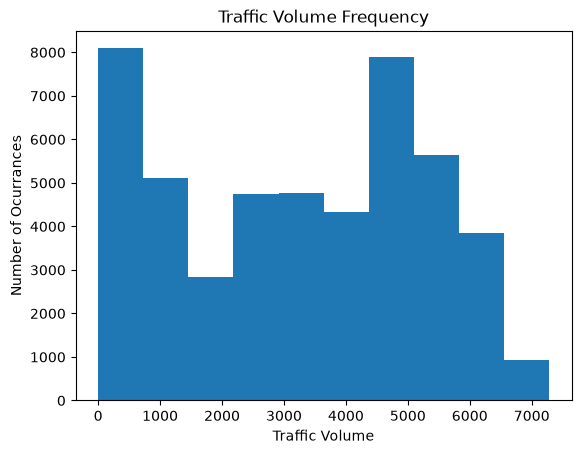

In [13]:
#histogram to examin 'traffic_volume'
plt.hist(metro['traffic_volume'])
plt.ylabel('Number of Ocurrances')
plt.xlabel('Traffic Volume')
plt.title('Traffic Volume Frequency')
plt.show()

Let's breakdown this graph. 
 
1) What does 'traffic volume' mean? In this case, traffic volume means the number of cars on the road at a given time.
2) On the x-axis we have the 'Traffic Volume' which means each bar represents a range of cars on the road regardless of time.
3) On the y-axis we have the 'Number of Occurances' which tells us the number of instances that traffic volume range occurs in the data set. 

For example, when there are about 0-500 cars on the road, that happens about 8,000 times in the dataset. That means that there are many instances when there are not many cars on the road. Another range that occurs about 8,000 times in the dataset is the range of 4,500-5,000 cars. Our next largest frequency is between 5,000-5,600ish cars. This suggests there are also many instances of heavy traffic on the road at a given time. 

In [12]:
#descriptive statistics
metro['traffic_volume'].describe()

count    48204.000000
mean      3259.818355
std       1986.860670
min          0.000000
25%       1193.000000
50%       3380.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64

From these statistics on the 'traffic_volume' column we can see that about a quarter of the time around 1,100 cars or fewer are on the road, half of the time 3,300 cars or fewer are on the road, and another three-quarter of the time around 4,900 cars or fewer are on the road. Only about 25% of the time are there upwards of 4,900 cars on the road. 

From the graph and these statistics we can determine there are times of high traffic, but what those time are, we don't know. That will be our next task: When are the times of high traffic? 

**Targeted Exploration: Day and Night**

We could probably guess what times traffic is the worst just from personal experiences. Traffic is usually worse around the morning and later afternoon work rush. To test this out, let's start by testing whether more traffic occurs at night (7 p.m. to 7 a.m.) or during the day (7 a.m. to 7 p.m.).

In [16]:
#convert 'date_time' column to datetime object
metro['date_time'] = pd.to_datetime(metro['date_time'])

In [18]:
#isolate hour from 'date_time' column
hour = metro['date_time'].dt.hour

In [22]:
#seperate data into day and night categories
day = metro.copy()[(hour >= 7) & (hour < 19)]
night = metro.copy()[(hour >= 19) | (hour < 7)]

print(f'Day: {day.shape}')
print('\n')
print(f'Night: {night.shape}')

Day: (23877, 9)


Night: (24327, 9)


The variables 'day' and 'night' contain all 9 columns of data from the 'metro' dataset. The 'day' variable contains all the data in the 'date_time' column when it occurs between 7 a.m. and 7 p.m.. The 'night' variable contains all the data in the 'date_time' column when it occurs between 7 p.m. and 7 a.m..

Together, the 'day' and 'night' variables hold the entire 'metro' dataset. That is, with the exception of a few rows that did not have hour values assigned to them (hence the difference between 23,877 and 24,327). To demonstrate this point, we will pull two examples of this from the 'metro' dataset.  

In [24]:
#pull sequential rows (176-177)
metro.iloc[176:178]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
176,NaN,281.17,0.0,0.0,90,Clouds,overcast clouds,2012-10-10 03:00:00,361
177,NaN,281.25,0.0,0.0,92,Clear,sky is clear,2012-10-10 06:00:00,5875


As you can see from the two rows present, the 'date_time' value jumps from 3:00 to 6:00. This means there was no data recorded at hour 4:00pm and 5:00pm on 2012-10-10. 

Now we will plot the 'day' dataset and 'night' dataset as a histogram. 

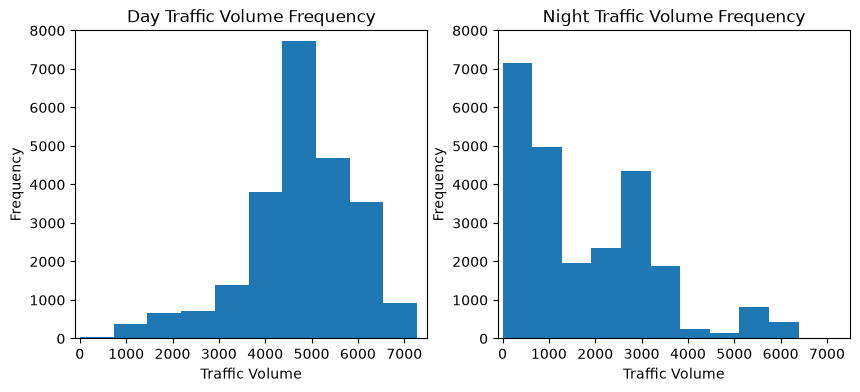

In [30]:
#set graph size
plt.figure(figsize=(10, 4))

#day subplot
plt.subplot(1, 2, 1)
plt.hist(day['traffic_volume'])
plt.xlabel('Traffic Volume')
plt.ylabel('Frequency')
plt.title('Day Traffic Volume Frequency')
plt.ylim(0, 8000)
plt.xlim(-100, 7500)

#night subplot
plt.subplot(1, 2, 2)
plt.hist(night['traffic_volume'])
plt.xlabel('Traffic Volume')
plt.ylabel('Frequency')
plt.title('Night Traffic Volume Frequency')
plt.ylim(0, 8000)
plt.xlim(-100, 7500)

plt.show()

From the two histograms above we can see that during the day, traffic volume is usually high with 4,000-6,5000 cars on the road being most common. At night, the most common traffic volume is typically lower with 0-1,000 cars being the most frequent at night. Let's look at some statistics for both histograms.

In [32]:
#descriptive statistics for 'day'
day['traffic_volume'].describe()

count    23877.000000
mean      4762.047452
std       1174.546482
min          0.000000
25%       4252.000000
50%       4820.000000
75%       5559.000000
max       7280.000000
Name: traffic_volume, dtype: float64

Similar to our observations in the histogram, most of the data collected during the day has anywhere from around 4,200 to 5,500 cars on the road. 

In [34]:
#descriptive statistics for 'night'
night['traffic_volume'].describe()

count    24327.000000
mean      1785.377441
std       1441.951197
min          0.000000
25%        530.000000
50%       1287.000000
75%       2819.000000
max       6386.000000
Name: traffic_volume, dtype: float64

This also reflects the 'night' histogram well with the data showing 50% of the time equal to or less than 1,300 cars are on the road. 75% of the time 2,800 cars are on the road.

**Conclusion**

As suspected, most cars are on the road during the day. We will use the 'day' data moving forward as it will give us more insight into when traffic jams are occuring.

## Traffic Volume: Time Indicators

Our next task is to identify what time indicators could predict a traffic jam during the day. We will analyze three time indicators:
* Month
* Day of the week
* Time of day

#### Month

Are there certain months that tend to have more traffic? We will test this by taking the mean of traffic volume per month and graphing it as a line graph. 

In [36]:
#create new column 'month' from day dataset and pull only month value from 'date_time' column
day['month'] = day['date_time'].dt.month

#variable that represents the mean of every column by month
by_month = day.groupby('month').mean(numeric_only=True)

by_month['traffic_volume']

month
1     4495.613727
2     4711.198394
3     4889.409560
4     4906.894305
5     4911.121609
6     4898.019566
7     4595.035744
8     4928.302035
9     4870.783145
10    4921.234922
11    4704.094319
12    4374.834566
Name: traffic_volume, dtype: float64

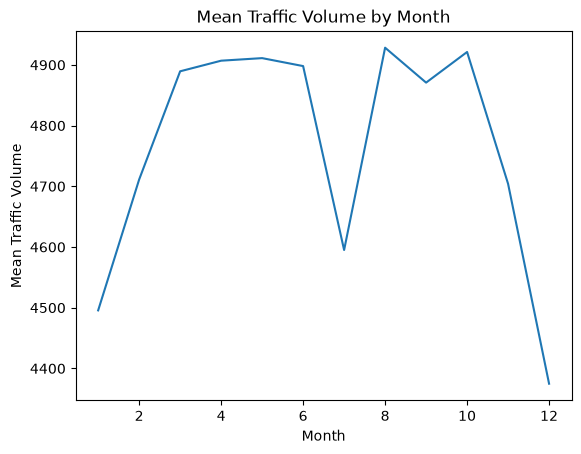

In [38]:
#line plot to track 'traffic-volume' by month
plt.plot(by_month['traffic_volume'])
plt.xlabel('Month')
plt.ylabel('Mean Traffic Volume')
plt.title('Mean Traffic Volume by Month')
plt.show()

For the most part, November through February (4 months) tend to have less traffic while March through October (8 months) have more. The warmer months (March-October) typically have around 4,900 cars on the road per day at any given time. 

An exception to this is in July when the mean drops substantially. Let's explore data in the month of July. 

In [39]:
#create new column 'year' from day dataset and pull only year value from 'date_time' column
day['year'] = day['date_time'].dt.year

#dataset with all columns and only rows with month as July
july = day[day['month'] == 7]

#variable that represents the mean of every column by year in month July
july_year = july.groupby('year').mean(numeric_only=True)

july_year['traffic_volume']

year
2013    4914.354054
2014    4871.598240
2015    4613.146226
2016    3924.923645
2017    4734.120301
2018    4586.899543
Name: traffic_volume, dtype: float64

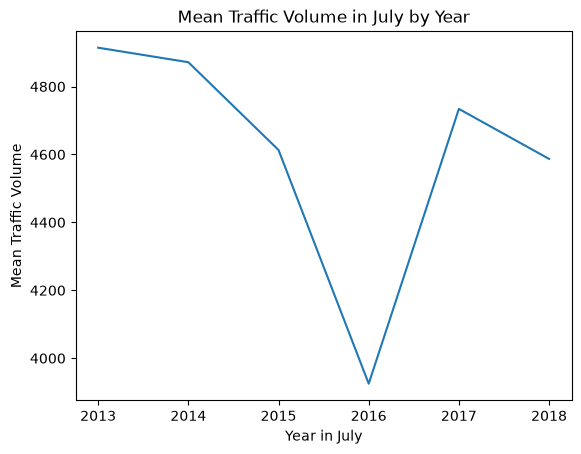

In [40]:
#line plot to track 'traffic-volume' by year in July
plt.plot(july_year['traffic_volume'])
plt.xlabel('Year in July')
plt.ylabel('Mean Traffic Volume')
plt.title('Mean Traffic Volume in July by Year')
plt.show()

It appears that most years, July has higher levels of traffic. The exception to this is in 2016. Likely this was due to some traffic pattern change like construction in the area. 

**Conclusion**

Overall, it can be stated that the warmer months (March-October) typically have more cars (around 4,900) on the road than the colder month (November-February) per day at any given time.

#### Day of the Week

Our next goal is to determine if there are certain days of the week were there are more cars on the road. We will do this by grouping the 'traffic_volume' data by day of the week and analyzing it on a line plot. 

In [41]:
#create new column 'day_of_week' from day dataset and pull only the day of the week value from 'date_time' column
day['day_of_week'] = day['date_time'].dt.dayofweek

#variable that represents the mean of every column by day of the week
day_of_week = day.groupby('day_of_week').mean(numeric_only=True)

day_of_week['traffic_volume'] # 0 is Monday and 6 is Sunday

day_of_week
0    4893.551286
1    5189.004782
2    5284.454282
3    5311.303730
4    5291.600829
5    3927.249558
6    3436.541789
Name: traffic_volume, dtype: float64

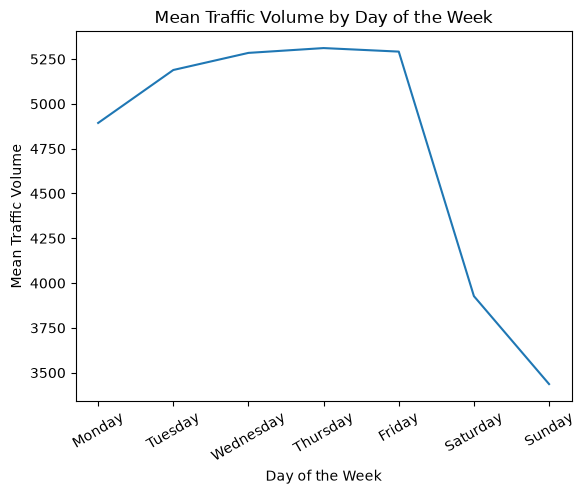

In [43]:
#line plot to track 'traffic-volume' by day of the week
plt.plot(day_of_week['traffic_volume'])
plt.xlabel('Day of the Week')
plt.ylabel('Mean Traffic Volume')
plt.title('Mean Traffic Volume by Day of the Week')
plt.xticks(ticks=[6, 0, 1, 2, 3, 4, 5], 
           labels=['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'], 
           rotation=30)
plt.show()

**Conclusion** 

It is no suprise that there tends to be more traffic during the weekdays (Monday-Friday) as more people are commuting to work on those days. 

#### Time of Day

Finally, we will look for traffic patterns based on the time of day. Since our previous analysis revealed there is more traffic during the week than on the weekends, we will split that data so our results are more accurate. Let's start by splitting the data. 

In [48]:
#create an hour column
day['hour'] = day['date_time'].dt.hour

#variable containing all the columns in day dataset with rows where 'day_of_week' is Sat/Sun
weekend = day.copy()[day['day_of_week'] >= 5] 

#variable containing all the columns in day dataset with rows where 'day_of_week' is Mon-Fri
weekdays = day.copy()[day['day_of_week'] <= 4]

#variable that represents the mean of every column by hour of day
hour_weekend = weekend.groupby('hour').mean(numeric_only=True)
hour_weekdays = weekdays.groupby('hour').mean(numeric_only=True)

print(f'Weekend: {hour_weekend['traffic_volume']}')
print('\n')
print(f'Weekdays: {hour_weekdays['traffic_volume']}')

Weekend: hour
7     1589.365894
8     2338.578073
9     3111.623917
10    3686.632302
11    4044.154955
12    4372.482883
13    4362.296564
14    4358.543796
15    4342.456881
16    4339.693805
17    4151.919929
18    3811.792279
Name: traffic_volume, dtype: float64


Weekdays: hour
7     6030.413559
8     5503.497970
9     4895.269257
10    4378.419118
11    4633.419470
12    4855.382143
13    4859.180473
14    5152.995778
15    5592.897768
16    6189.473647
17    5784.827133
18    4434.209431
Name: traffic_volume, dtype: float64


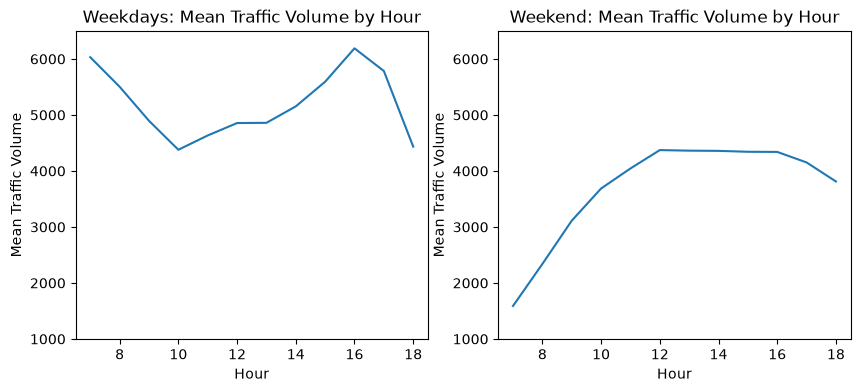

In [52]:
#set graph size
plt.figure(figsize=(10, 4))

#weekdays subplot
plt.subplot(1, 2, 1)
plt.plot(hour_weekdays['traffic_volume'])
plt.xlabel('Hour')
plt.ylabel('Mean Traffic Volume')
plt.title('Weekdays: Mean Traffic Volume by Hour')
plt.ylim(1000, 6500)
plt.xlim(6.5, 18.5)

#weekend subplot
plt.subplot(1, 2, 2)
plt.plot(hour_weekend['traffic_volume'])
plt.xlabel('Hour')
plt.ylabel('Mean Traffic Volume')
plt.title('Weekend: Mean Traffic Volume by Hour')
plt.ylim(1000, 6500)
plt.xlim(6.5, 18.5)

plt.show()

**Conclusion**

During the week, most cars are on the road from 7-8 a.m. and 4-5 p.m. - likely as people are going to and from work. 

On the weekend, not many cars are on the road in the early morning. From 7 a.m. to 12 p.m. the traffic is steadily increasing and then remaining stagnant with around 4,500 cars on the road the remained of the day (until 7 p.m.).

#### Traffic Volume: Time Indicators *Summary*

Given our analysis, below are the three time indicators of traffic volume: 
1) Warmer months (March-October) typically have more cars on the road than the colder month (November-February) per day at any given time
2) Traffic is higher during the weekdays (Monday-Friday) and lesser on the weekends
3) During the week, most cars are on the road from 7-8 a.m. and 4-5 p.m. while weekend traffic is more stagnant

## Traffic Volume: Weather Indicators

There are six columns in our dataset that have information regarding weather: 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', and 'weather_description'. 

* 'temp', 'rain_1h', 'snow_1h', and 'clouds_all' are numerical dtypes
* 'weather_main' and 'weather_description' are string dtypes

We will start by looking at the Pearson correlation values between the numerical dtypes and the 'traffic_volume' dtype. 

**Numerical Dtypes**

In [57]:
#'temp' and 'traffic_volume' Pearson correlation
float(day['temp'].corr(day['traffic_volume']))

0.12831656852303913

In [58]:
#'rain_1h' and 'traffic_volume' Pearson correlation
float(day['rain_1h'].corr(day['traffic_volume']))

0.0036965098350734264

In [59]:
#'snow_1h' and 'traffic_volume' Pearson correlation
float(day['snow_1h'].corr(day['traffic_volume']))

0.001265349847175984

In [60]:
#'clouds_all' and 'traffic_volume' Pearson correlation
float(day['clouds_all'].corr(day['traffic_volume']))

-0.032932348661639486

The correlation between 'temp' and 'traffic' is the strongest of the four correlation values. Let's plot a scatter plot to see what the correlation looks like. 

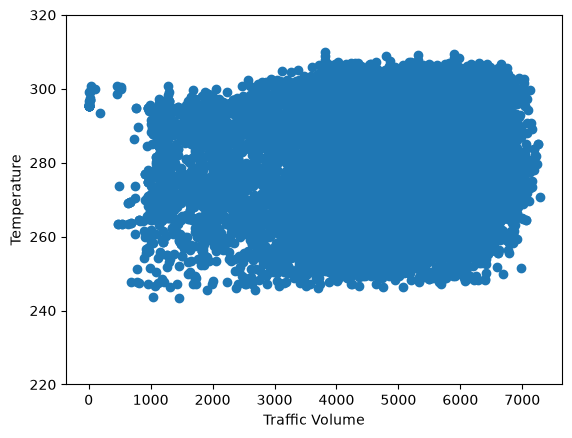

In [68]:
#scatter plot to analyze the correlation between 'temp' and 'traffic_volume'
plt.scatter(day['traffic_volume'], day['temp'])
plt.xlabel('Traffic Volume')
plt.ylabel('Temperature')
plt.ylim(220, 320)
plt.show()

Given the weak +0.13 Pearson correlation between 'temp' and 'traffic_volume' it's no suprise the graph does not reflect a correlation either. Let's try to analyze 'weather_main' and 'weather_description' against 'traffic_volume' next to see if there is a relationship.

**String Dtypes**

The way we will analyze the relationship between 'weather_main' against 'traffic_volume' is by grouping the dataset by 'weather_main' and taking the mean of the 'traffic_volume' on those days. We will do the same for the 'weather_description' column.

In [69]:
#variable that represents the mean of every column grouped by 'weather_main'
weather_main = day.groupby('weather_main').mean(numeric_only=True)
weather_main['traffic_volume']

weather_main
Clear           4778.416260
Clouds          4865.415996
Drizzle         4837.212911
Fog             4372.491713
Haze            4609.893285
Mist            4623.976475
Rain            4815.568462
Smoke           4564.583333
Snow            4396.321183
Squall          4211.000000
Thunderstorm    4648.212860
Name: traffic_volume, dtype: float64

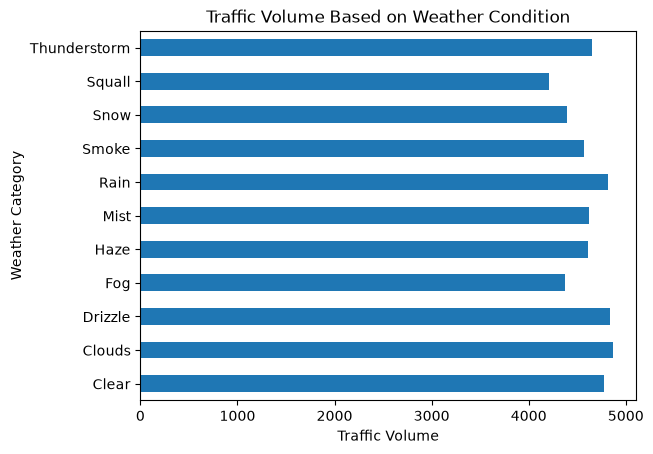

In [85]:
#horizontal bar graph of relationship between 'traffic_volume' and 'weather_main'
weather_main['traffic_volume'].plot.barh()
plt.xlabel('Traffic Volume')
plt.ylabel('Weather Category')
plt.title('Traffic Volume Based on Weather Condition')
plt.show()

Most traffic volume is still between 4,000 and 5,000 cars on the road regardless of the weather condition. Squall, snow, and fog are the weather conditions that tend to have the least number of cars on the road, while clouds, clear and, rainy conditions have the most number of cars on the road. There is no obvious indicator here. Let's repeat this process with 'weather_description'.

In [86]:
#variable that represents the mean of every column grouped by 'weather_description'
weather_description = day.groupby('weather_description').mean(numeric_only=True)
weather_description['traffic_volume']

weather_description
SQUALLS                                4211.000000
Sky is Clear                           4919.009390
broken clouds                          4824.130326
drizzle                                4737.330935
few clouds                             4839.818023
fog                                    4372.491713
freezing rain                          4314.000000
haze                                   4609.893285
heavy intensity drizzle                4738.586207
heavy intensity rain                   4610.356164
heavy snow                             4411.681250
light intensity drizzle                4890.164049
light intensity shower rain            4558.100000
light rain                             4859.650849
light rain and snow                    5579.750000
light shower snow                      4618.636364
light snow                             4430.858896
mist                                   4623.976475
moderate rain                          4769.643312
overcast cl

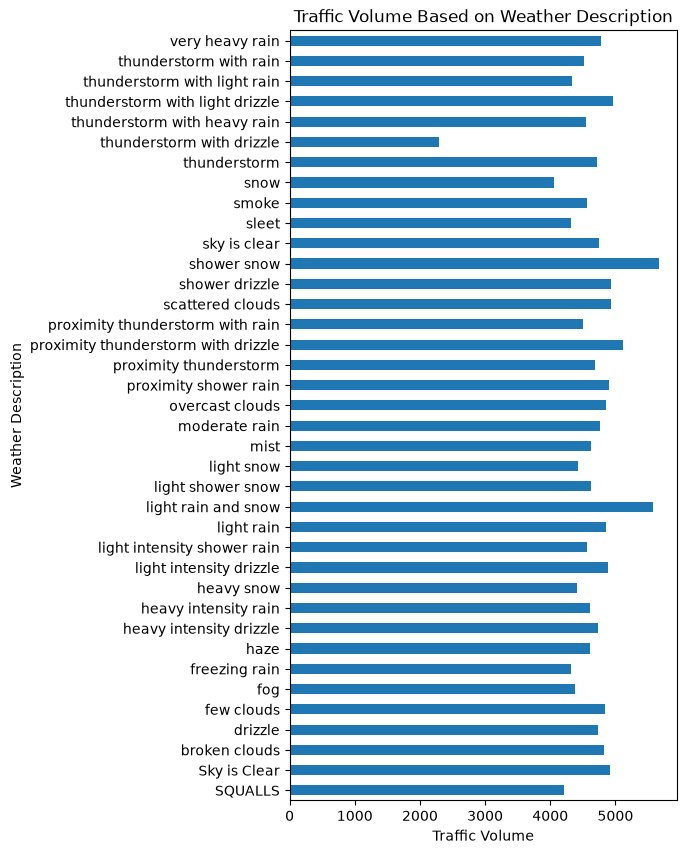

In [94]:
#horizontal bar graph of relationship between 'traffic_volume' and 'weather_description'
weather_description['traffic_volume'].plot.barh(figsize=(5, 10))
plt.xlabel('Traffic Volume')
plt.ylabel('Weather Description')
plt.title('Traffic Volume Based on Weather Description')
plt.show()

In [98]:
#isolate weather conditions where there are 5000 or more cars on the road
weather_traffic = weather_description.copy()[weather_description['traffic_volume'] >= 5000]
weather_traffic['traffic_volume']

weather_description
light rain and snow                    5579.750000
proximity thunderstorm with drizzle    5121.833333
shower snow                            5664.000000
Name: traffic_volume, dtype: float64

The bar graph representing the data is difficult to read, so we isolated weather descriptions where the traffic volume was over 5,000 cars. 

Traffic is worse during: 'light rain and snow', 'proximity thunderstorm with drizzle', and 'shower snow' weather conditions. 

It is unclear why these weather conditions have a correlation to more traffic on the road; Perhaps the reason these weather conditions are related to greater traffic is because they appear relatively harmless on the weather forcast so people don't alter their plans. However, perhaps once on the condition onsets, the road visibility decreases and causes traffic to move slower than usual.

#### Traffic Volume: Weather Indicators *Summary*

Unlike the time indicators, weather indicators were more difficult to atain. The only weather conditions that were linked to more traffic on the roads were:
* light rain and snow
* proximity thunderstorm with drizzle
* shower snow

## I-94 Interstate Highway: Predicting Traffic *Conclusion*

Three time indicators of traffic volume:

* Warmer months (March-October) typically have more cars on the road than the colder month (November-February) per day at any given time
* Traffic is higher during the weekdays (Monday-Friday) and lesser on the weekends
* During the week, most cars are on the road from 7-8 a.m. and 4-5 p.m. while weekend traffic is more stagnant

Three weather condition indicators of traffic volume:

* Light rain and snow
* Proximity thunderstorm with drizzle
* Shower snow